In [2]:
# Importing the required libraries
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

In [3]:
#Reading CSV files
from google.colab import files
files.upload()

Saving Life_Expectancy_Data.csv to Life_Expectancy_Data.csv


{'Life_Expectancy_Data.csv': b'Country,Continent,Year,Status,Life_expectancy ,Adult_Mortality,infant_deaths,Alcohol,percentage_expenditure,Hepatitis_B,Measles , BMI ,under_five_deaths ,Polio,Total_expenditure,Diphtheria , HIV/AIDS,GDP,Population, thinness  1-19 years, thinness 5-9 years,Income_composition_of_resources,Schooling\nAfghanistan,Asia,2015,Developing,65,263,62,0.01,71.27962362,65,1154,19.1,83,6,8.16,65,0.1,584.25921,33736494,17.2,17.3,0.479,10.1\nAfghanistan,Asia,2014,Developing,59.9,271,64,0.01,73.52358168,62,492,18.6,86,58,8.18,62,0.1,612.696514,327582,17.5,17.5,0.476,10\nAfghanistan,Asia,2013,Developing,59.9,268,66,0.01,73.21924272,64,430,18.1,89,62,8.13,64,0.1,631.744976,31731688,17.7,17.7,0.47,9.9\nAfghanistan,Asia,2012,Developing,59.5,272,69,0.01,78.1842153,67,2787,17.6,93,67,8.52,67,0.1,669.959,3696958,17.9,18,0.463,9.8\nAfghanistan,Asia,2011,Developing,59.2,275,71,0.01,7.097108703,68,3013,17.2,97,68,7.87,68,0.1,63.537231,2978599,18.2,18.2,0.454,9.5\nAfghanistan,Asia,

In [4]:
df = pd.read_csv('Life_Expectancy_Data.csv')
df

,Country,Continent,Year,Status,Life_expectancy,Adult_Mortality,infant_deaths,Alcohol,percentage_expenditure,Hepatitis_B,...,Polio,Total_expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income_composition_of_resources,Schooling
0,Afghanistan,Asia,2015,Developing,65.0,263,62,0.01,71.279624,65.0,...,6.0,8.16,65,0.1,584.259210,33736494,17.2,17.3,0.479,10.1
1,Afghanistan,Asia,2014,Developing,59.9,271,64,0.01,73.523582,62.0,...,58.0,8.18,62,0.1,612.696514,327582,17.5,17.5,0.476,10.0
2,Afghanistan,Asia,2013,Developing,59.9,268,66,0.01,73.219243,64.0,...,62.0,8.13,64,0.1,631.744976,31731688,17.7,17.7,0.470,9.9
3,Afghanistan,Asia,2012,Developing,59.5,272,69,0.01,78.184215,67.0,...,67.0,8.52,67,0.1,669.959000,3696958,17.9,18.0,0.463,9.8
4,Afghanistan,Asia,2011,Developing,59.2,275,71,0.01,7.097109,68.0,...,68.0,7.87,68,0.1,63.537231,2978599,18.2,18.2,0.454,9.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2456,Zimbabwe,Africa,2004,Developing,44.3,723,27,4.36,0.000000,68.0,...,67.0,7.13,65,33.6,454.366654,12777511,9.4,9.4,0.407,9.2
2457,Zimbabwe,Africa,2003,Developing,44.5,715,26,4.06,0.000000,7.0,...,7.0,6.52,68,36.7,453.351155,12633897,9.8,9.9,0.418,9.5
2458,Zimbabwe,Africa,2002,Developing,44.8,73,25,4.43,0.000000,73.0,...,73.0,6.53,71,39.8,57.348340,125525,1.2,1.3,0.427,10.0
2459,Zimbabwe,Africa,2001,Developing,45.3,686,25,1.72,0.000000,76.0,...,76.0,6.16,75,42.1,548.587312,12366165,1.6,1.7,0.427,9.8


In [5]:
# Кількість вимірів
print(df.shape)

# Дивимося на вигляд даних
print(df.head(10))

# Фічі датасету
print(df.columns)

# Отримуємо загальну інформацію про датасет
print(df.describe(include='all'))

(2461, 23)
       Country Continent  Year      Status  Life_expectancy   Adult_Mortality  \
0  Afghanistan      Asia  2015  Developing              65.0              263   
1  Afghanistan      Asia  2014  Developing              59.9              271   
2  Afghanistan      Asia  2013  Developing              59.9              268   
3  Afghanistan      Asia  2012  Developing              59.5              272   
4  Afghanistan      Asia  2011  Developing              59.2              275   
5  Afghanistan      Asia  2010  Developing              58.8              279   
6  Afghanistan      Asia  2009  Developing              58.6              281   
7  Afghanistan      Asia  2008  Developing              58.1              287   
8  Afghanistan      Asia  2007  Developing              57.5              295   
9  Afghanistan      Asia  2006  Developing              57.3              295   

   infant_deaths  Alcohol  percentage_expenditure  Hepatitis_B  ...  Polio  \
0             62   

In [6]:
print(df['Diphtheria '].value_counts(dropna=False))

Diphtheria 
99    288
98    218
97    174
95    167
96    164
     ... 
16      1
31      1
21      1
19      1
27      1
Name: count, Length: 81, dtype: int64


In [7]:
# Замінюємо "N/A" та "Unknown" на NaN у числових стовпцях
df.replace({"N/A": np.nan, "Unknown": np.nan}, inplace=True)

df['Hepatitis_B'] = pd.to_numeric(df['Hepatitis_B'], errors='coerce')
df['Polio'] = pd.to_numeric(df['Polio'], errors='coerce')
df['Total_expenditure'] = pd.to_numeric(df['Total_expenditure'], errors='coerce')
df['Diphtheria '] = pd.to_numeric(df['Diphtheria '], errors='coerce')
df['Population'] = pd.to_numeric(df['Population'], errors='coerce')

# Підрахунок значень у стовпцях
print(df['Hepatitis_B'].value_counts(dropna=False))
print(df['Polio'].value_counts(dropna=False))
print(df['Total_expenditure'].value_counts(dropna=False))
print(df['Diphtheria '].value_counts(dropna=False))
print(df['Population'].value_counts(dropna=False))

# Видалення рядків з пропущеними значеннями у вибраних стовпцях
df = df.dropna(subset=['Polio', 'Diphtheria ', 'Income_composition_of_resources', 'Schooling', 'Total_expenditure'])

# Обчислення середніх значень для кожного континенту
averages = df.groupby('Continent').agg(
    mean_Hepatitis_B=('Hepatitis_B', 'mean'),
    mean_Population=('Population', 'mean')
).reset_index()

print(averages)

Hepatitis_B
NaN     464
98.0    182
99.0    181
96.0    144
95.0    132
       ... 
26.0      1
16.0      1
23.0      1
15.0      1
21.0      1
Name: count, Length: 85, dtype: int64
Polio
99.0    305
98.0    218
96.0    175
97.0    169
95.0    159
       ... 
48.0      2
23.0      1
17.0      1
35.0      1
32.0      1
Name: count, Length: 73, dtype: int64
Total_expenditure
NaN     152
4.60     14
6.70     10
5.60     10
4.20      9
       ... 
2.27      1
9.53      1
8.64      1
7.27      1
3.52      1
Name: count, Length: 772, dtype: int64
Diphtheria 
99.0    288
98.0    218
97.0    174
95.0    167
96.0    164
       ... 
16.0      1
31.0      1
21.0      1
19.0      1
27.0      1
Name: count, Length: 81, dtype: int64
Population
NaN           223
444.0           4
1141.0          2
26868.0         2
718239.0        2
             ... 
1444844.0       1
1489193.0       1
1536411.0       1
1586754.0       1
12222251.0      1
Name: count, Length: 2232, dtype: int64
       Continent  mean

In [8]:
# Заповнення пропущених значень у стовпцях Hepatitis_B та Population середніми значеннями по континентах
df = df.merge(averages, on='Continent', how='left')

df['Hepatitis_B'] = df['Hepatitis_B'].fillna(df['mean_Hepatitis_B'])
df['Population'] = df['Population'].fillna(df['mean_Population'])

# Видаляємо тимчасові стовпці зі середніми значеннями
df = df.drop(columns=['mean_Hepatitis_B', 'mean_Population'])

# Кількість пропущених значень після обробки
print(df.isna().sum())

Country                            0
Continent                          0
Year                               0
Status                             0
Life_expectancy                    0
Adult_Mortality                    0
infant_deaths                      0
Alcohol                            0
percentage_expenditure             0
Hepatitis_B                        0
Measles                            0
 BMI                               0
under_five_deaths                  0
Polio                              0
Total_expenditure                  0
Diphtheria                         0
 HIV/AIDS                          0
GDP                                0
Population                         0
 thinness  1-19 years              0
 thinness 5-9 years                0
Income_composition_of_resources    0
Schooling                          0
dtype: int64


In [9]:
df

,Country,Continent,Year,Status,Life_expectancy,Adult_Mortality,infant_deaths,Alcohol,percentage_expenditure,Hepatitis_B,...,Polio,Total_expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income_composition_of_resources,Schooling
0,Afghanistan,Asia,2015,Developing,65.0,263,62,0.01,71.279624,65.0,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,Asia,2014,Developing,59.9,271,64,0.01,73.523582,62.0,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,Asia,2013,Developing,59.9,268,66,0.01,73.219243,64.0,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,Asia,2012,Developing,59.5,272,69,0.01,78.184215,67.0,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,Asia,2011,Developing,59.2,275,71,0.01,7.097109,68.0,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2296,Zimbabwe,Africa,2004,Developing,44.3,723,27,4.36,0.000000,68.0,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2297,Zimbabwe,Africa,2003,Developing,44.5,715,26,4.06,0.000000,7.0,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2298,Zimbabwe,Africa,2002,Developing,44.8,73,25,4.43,0.000000,73.0,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2299,Zimbabwe,Africa,2001,Developing,45.3,686,25,1.72,0.000000,76.0,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8


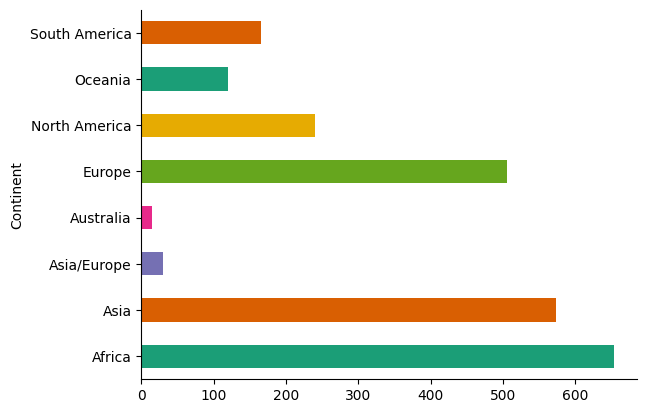

In [10]:
from matplotlib import pyplot as plt
import seaborn as sns
df.groupby('Continent').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

In [11]:
df['Status'].unique()
from sklearn.preprocessing import LabelEncoder

# Створюємо об'єкт LabelEncoder
le = LabelEncoder()

# Закодовуємо колонку "Status"
df['Status'] = le.fit_transform(df['Status'])

# Перевіряємо результат
print(df['Status'].value_counts())
print(df[['Status']].head())

Status
1    1881
0     420
Name: count, dtype: int64
   Status
0       1
1       1
2       1
3       1
4       1


In [ ]:
# Feature matrix (всі колонки, крім 'Continent')
X = df.drop(columns=['Continent', 'Country'])

# Target variable (One-Hot Encoding для 'Continent')
y = le.fit_transform(df['Continent'])

# Перевіряємо, чи правильно закодувалось
print(y)

[1 1 1 ... 0 0 0]


In [ ]:
# now lets split the data into train and test
from sklearn.model_selection import train_test_split

In [ ]:
# Splitting the data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)
X_train.shape, X_test.shape

((1610, 21), (691, 21))

In [ ]:
from sklearn.ensemble import RandomForestClassifier
classifier_rf = RandomForestClassifier(random_state=42,  max_depth=5,
                                       n_estimators=100, oob_score=True)

In [ ]:
classifier_rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, oob_score=True, random_state=42)

In [ ]:
# @title Визначимо наскільки точними є прогнози дерев для тих спостережень, які не увійшли у підсет для їх побудови. Також така техніка може бути використана, коли даних мало і розділити на навчальну та тестову частину не має можливості.
# checking the oob score
classifier_rf.oob_score_

0.8559006211180125

In [ ]:
# @title Налаштування гіперпараметрів max_features="sqrt", "log2", criterion="gini" або "entropy")
rf = RandomForestClassifier(random_state=42, max_features="sqrt", criterion="entropy")

In [ ]:
params = {
    'max_depth': [2,3,5,10,20],
    'min_samples_leaf': [5,10,20,50,100,200],
    'n_estimators': [5,10,25,30,50,100]
}

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
#  Instantiate the grid search model
grid_search = GridSearchCV(estimator=rf,
                           param_grid=params,
                           cv = 4,
                           scoring="accuracy")

In [ ]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=4,
             estimator=RandomForestClassifier(criterion='entropy',
                                              random_state=42),
             param_grid={'max_depth': [2, 3, 5, 10, 20],
                         'min_samples_leaf': [5, 10, 20, 50, 100, 200],
                         'n_estimators': [5, 10, 25, 30, 50, 100]},
             scoring='accuracy')

In [ ]:
# @title Вивід найкращої точності
grid_search.best_score_

0.9645908176240385

In [ ]:
# @title Вивід найкращих гіперпараметрів
rf_best = grid_search.best_estimator_
rf_best

RandomForestClassifier(criterion='entropy', max_depth=20, min_samples_leaf=5,
                       random_state=42)

In [ ]:
print(le.classes_)

['Africa' 'Asia' 'Asia/Europe' 'Australia' 'Europe' 'North America'
 'Oceania' 'South America']


In [ ]:
y

array([1, 1, 1, ..., 0, 0, 0])

In [ ]:
rf_best.estimators_[5]

DecisionTreeClassifier(criterion='entropy', max_depth=20, max_features='sqrt',
                       min_samples_leaf=5, random_state=1201263687)

In [ ]:
# Перегляд ймовірностей для кожного листка дерева
estimator = rf_best.estimators_[5]  # Наприклад, вибираємо 5-е дерево

# Отримуємо ймовірності класів для кожного листка дерева
class_probabilities = estimator.tree_.value

# Показуємо ймовірності для першого листка
print(class_probabilities[0])

# Ви можете перевірити ймовірності для кожного листка, щоб побачити, який клас має найбільшу ймовірність



[[0.28198758 0.2484472  0.01428571 0.00372671 0.23229814 0.09378882
  0.04409938 0.08136646]]


In [ ]:
# @title Побудова 5-го дерева прийняття рішень
from sklearn.tree import plot_tree
plt.figure(figsize=(100,100))
plot_tree(rf_best.estimators_[5], feature_names = X.columns,class_names=['Africa', 'Asia', 'Asia/Europe', 'Australia', 'Europe', 'North America',
 'Oceania', 'South America'],filled=True);

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# @title Побудова 7-го дерева прийняття рішень
from sklearn.tree import plot_tree
plt.figure(figsize=(200,140))
plot_tree(rf_best.estimators_[7], feature_names = X.columns,class_names=['Africa', 'Asia', 'Asia/Europe', 'Australia', 'Europe', 'North America',
 'Oceania', 'South America'],filled=True);

Output hidden; open in https://colab.research.google.com to view.

Перевірка точності на тестовій вибірці

In [ ]:
from sklearn.metrics import accuracy_score

y_pred = rf_best.predict(X_test)  # Передбачення на тестовій вибірці
accuracy = accuracy_score(y_test, y_pred)  # Обчислення точності
print(f"Accuracy on test data: {accuracy:.4f}")


Accuracy on test data: 0.9711


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=['Africa', 'Asia', 'Asia/Europe', 'Australia', 'Europe', 'North America','Oceania', 'South America']))

               precision    recall  f1-score   support

       Africa       0.99      1.00      0.99       203
         Asia       0.98      0.97      0.98       158
  Asia/Europe       1.00      0.86      0.92         7
    Australia       1.00      1.00      1.00         6
       Europe       0.95      0.99      0.97       148
North America       0.95      0.88      0.91        84
      Oceania       1.00      1.00      1.00        35
South America       0.96      0.96      0.96        50

     accuracy                           0.97       691
    macro avg       0.98      0.96      0.97       691
 weighted avg       0.97      0.97      0.97       691



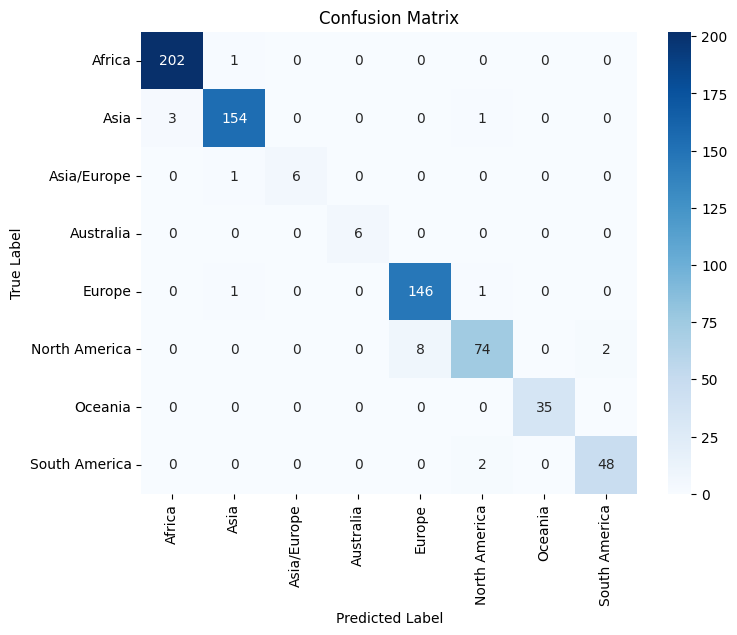

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Класові мітки
class_labels = ['Africa', 'Asia', 'Asia/Europe', 'Australia', 'Europe', 'North America', 'Oceania', 'South America']

# Обчислення матриці помилок
cm = confusion_matrix(y_test, y_pred)

# Візуалізація
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# @title Дерева, створені estimators_[5] і estimators_[7], різні. Таким чином, можна сказати, що кожне дерево не залежить від іншого. Виведемо наскільки впливають ознаки на класову ознаку
rf_best.feature_importances_

array([0.00339831, 0.04427341, 0.07997882, 0.03367907, 0.04074488,
       0.13585298, 0.00383162, 0.01217502, 0.04680297, 0.04946741,
       0.04820863, 0.01158357, 0.02498986, 0.01124206, 0.07353867,
       0.00725758, 0.02053134, 0.12616138, 0.11268676, 0.06810043,
       0.04549524])

In [ ]:
imp_df = pd.DataFrame({
    "Varname": X_train.columns,
    "Imp": rf_best.feature_importances_
})

In [ ]:
imp_df.sort_values(by="Imp", ascending=False)

,Varname,Imp
5,Alcohol,0.135853
17,thinness 1-19 years,0.126161
18,thinness 5-9 years,0.112687
2,Life_expectancy,0.079979
14,HIV/AIDS,0.073539
19,Income_composition_of_resources,0.068100
9,BMI,0.049467
10,under_five_deaths,0.048209
8,Measles,0.046803
20,Schooling,0.045495


In [ ]:
print(df.columns)

Index(['Country', 'Continent', 'Year', 'Status', 'Life_expectancy ',
       'Adult_Mortality', 'infant_deaths', 'Alcohol', 'percentage_expenditure',
       'Hepatitis_B', 'Measles ', ' BMI ', 'under_five_deaths ', 'Polio',
       'Total_expenditure', 'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population',
       ' thinness  1-19 years', ' thinness 5-9 years',
       'Income_composition_of_resources', 'Schooling'],
      dtype='object')


In [ ]:
# @title Спробуємо покращити результати використовуючи лише найбільш важливі ознаки
Z= df[['Alcohol',' thinness  1-19 years']]

In [ ]:
Z_train, Z_test, y_train, y_test = train_test_split(Z, y, train_size=0.7, random_state=42)
Z_train.shape, Z_test.shape

((1610, 2), (691, 2))

In [ ]:
Z_train

,Alcohol,thinness 1-19 years
999,0.06,1.9
680,0.49,9.1
694,15.04,2.0
888,3.21,8.0
352,4.55,9.3
...,...,...
1638,0.01,1.3
1095,0.59,3.8
1130,1.43,8.7
1294,1.10,7.7


In [ ]:
grid_search.fit(Z_train, y_train)

GridSearchCV(cv=4,
             estimator=RandomForestClassifier(criterion='entropy',
                                              random_state=42),
             param_grid={'max_depth': [2, 3, 5, 10, 20],
                         'min_samples_leaf': [5, 10, 20, 50, 100, 200],
                         'n_estimators': [5, 10, 25, 30, 50, 100]},
             scoring='accuracy')

In [ ]:
grid_search.best_score_

0.8018669061639693

Результат погіршився, можна спробувати зменшити розмірність методом PCA, t-SNE щоб збільшити точність

In [ ]:
rf_best = grid_search.best_estimator_
rf_best

RandomForestClassifier(criterion='entropy', max_depth=20, min_samples_leaf=5,
                       n_estimators=10, random_state=42)

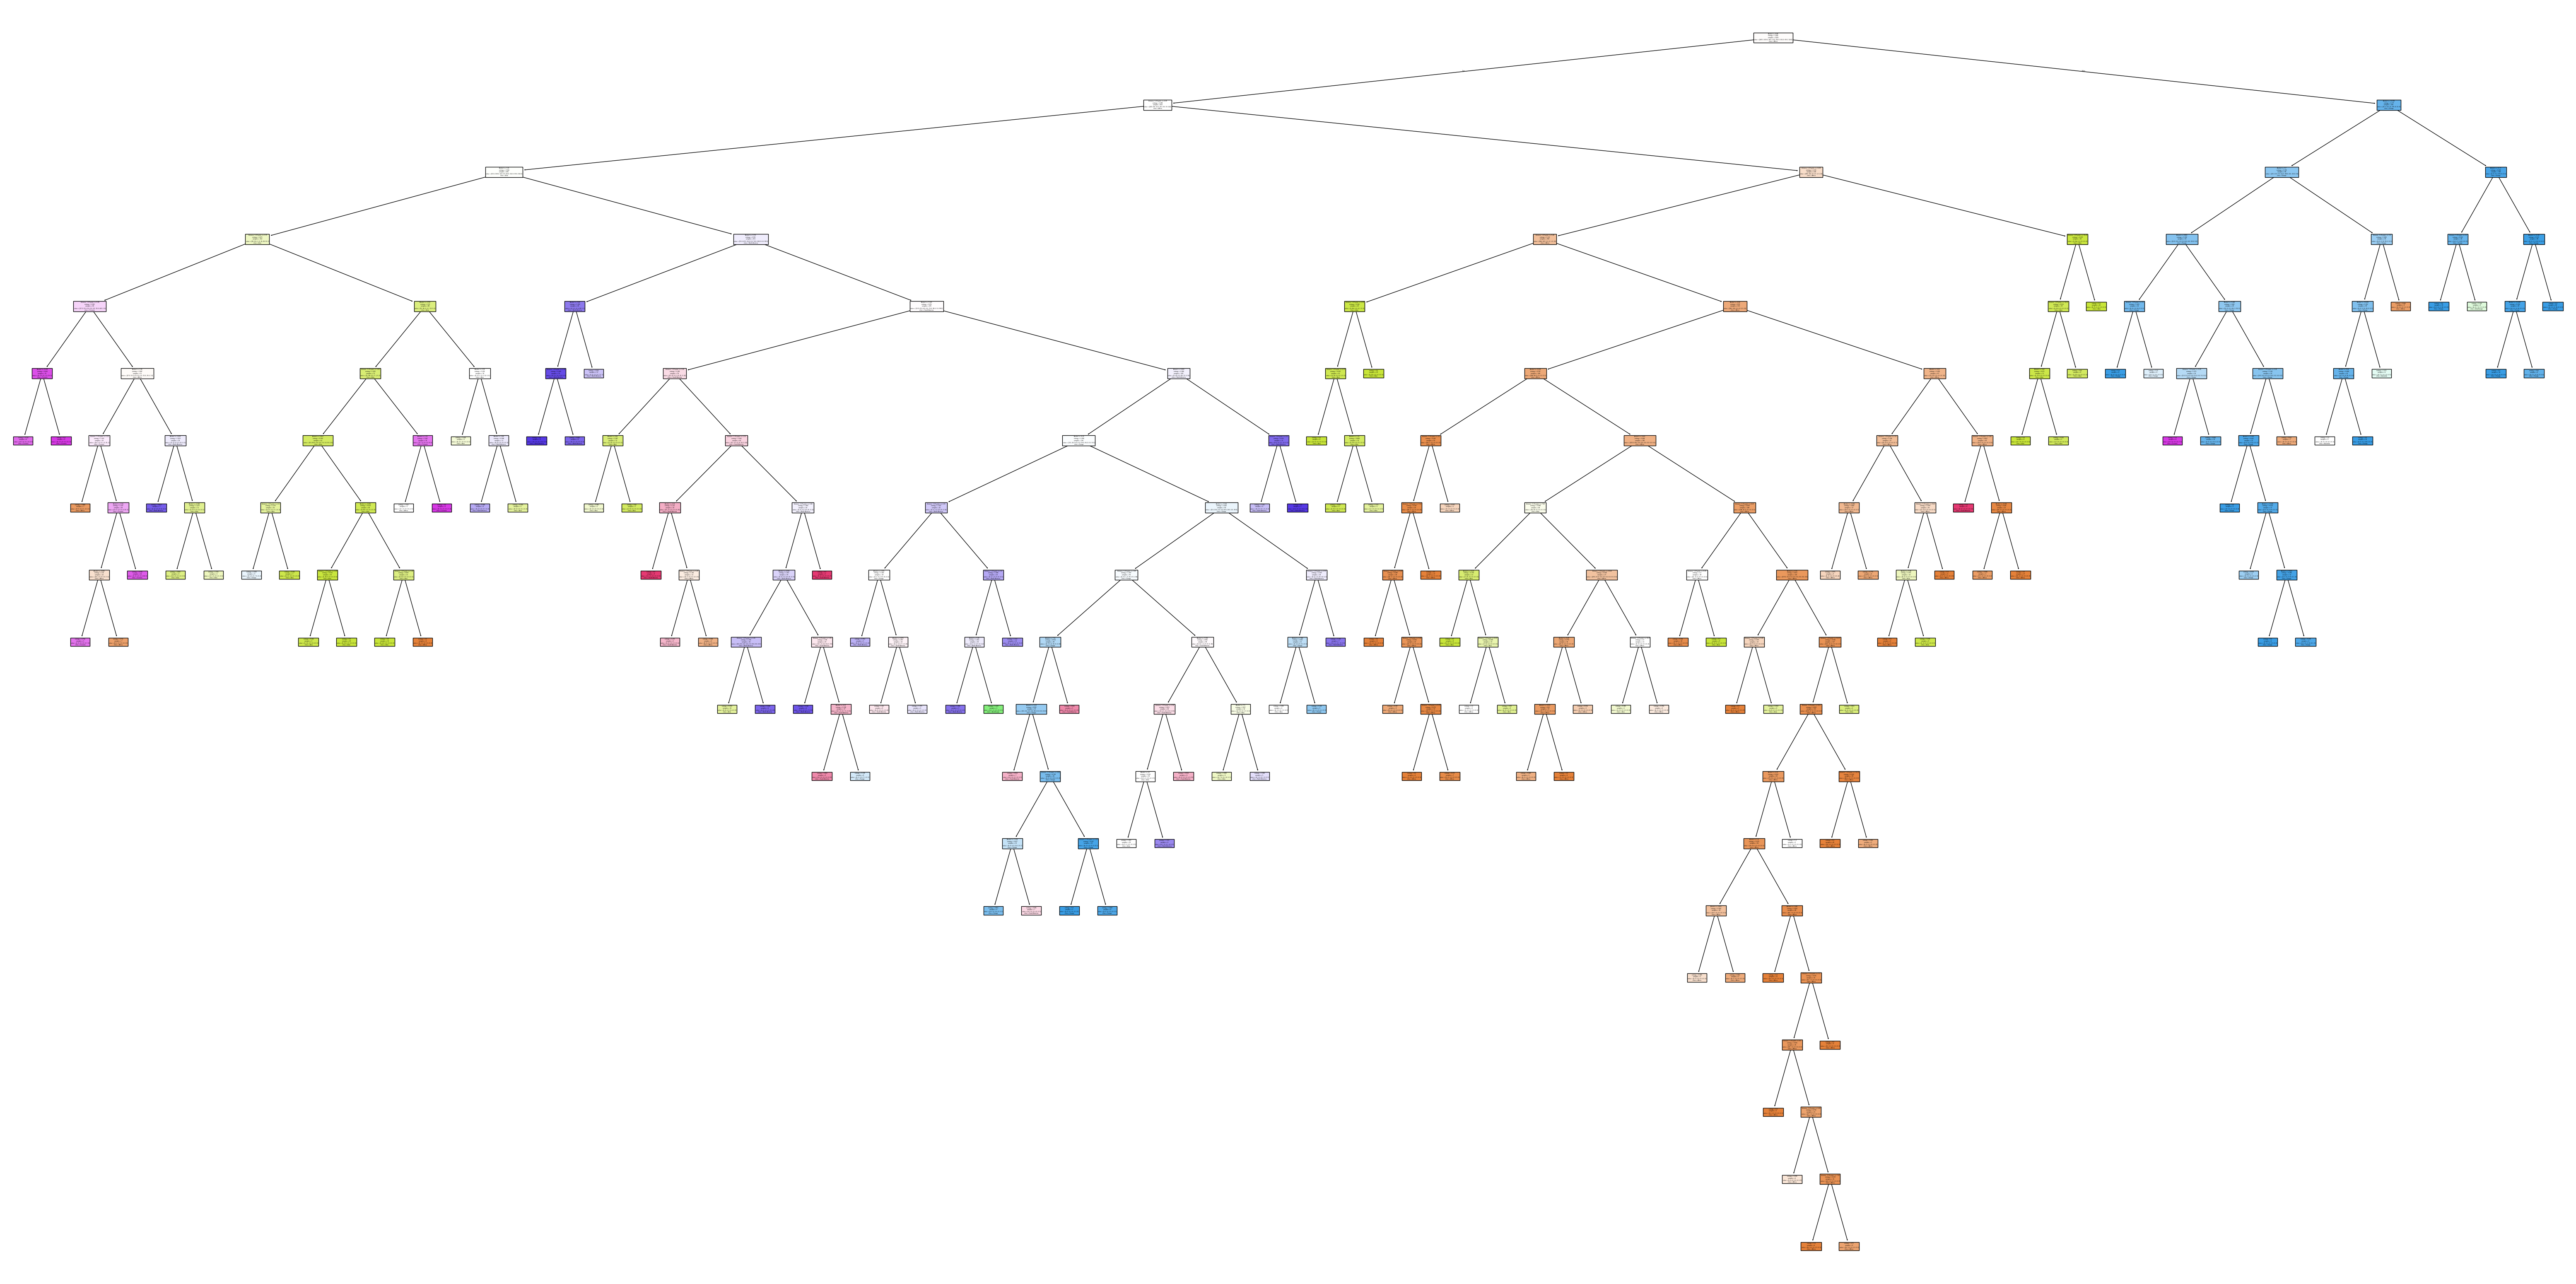

In [ ]:
from sklearn.tree import plot_tree
plt.figure(figsize=(80,40))
plot_tree(rf_best.estimators_[7], feature_names = Z.columns,class_names=['Africa', 'Asia', 'Asia/Europe', 'Australia', 'Europe', 'North America',
 'Oceania', 'South America'],filled=True);

Подивимося чи можна збільшити точність використавши метод PCA

In [ ]:
# Перекодування колонки Continent
df['Continent'] = le.fit_transform(df['Continent'])

# Видалення колонки Country
df = df.drop(columns=['Country'])
df

,Continent,Year,Status,Life_expectancy,Adult_Mortality,infant_deaths,Alcohol,percentage_expenditure,Hepatitis_B,Measles,...,Polio,Total_expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income_composition_of_resources,Schooling
0,1,2015,1,65.0,263,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,1,2014,1,59.9,271,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,1,2013,1,59.9,268,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,1,2012,1,59.5,272,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,1,2011,1,59.2,275,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2296,0,2004,1,44.3,723,27,4.36,0.000000,68.0,31,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2297,0,2003,1,44.5,715,26,4.06,0.000000,7.0,998,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2298,0,2002,1,44.8,73,25,4.43,0.000000,73.0,304,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2299,0,2001,1,45.3,686,25,1.72,0.000000,76.0,529,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8


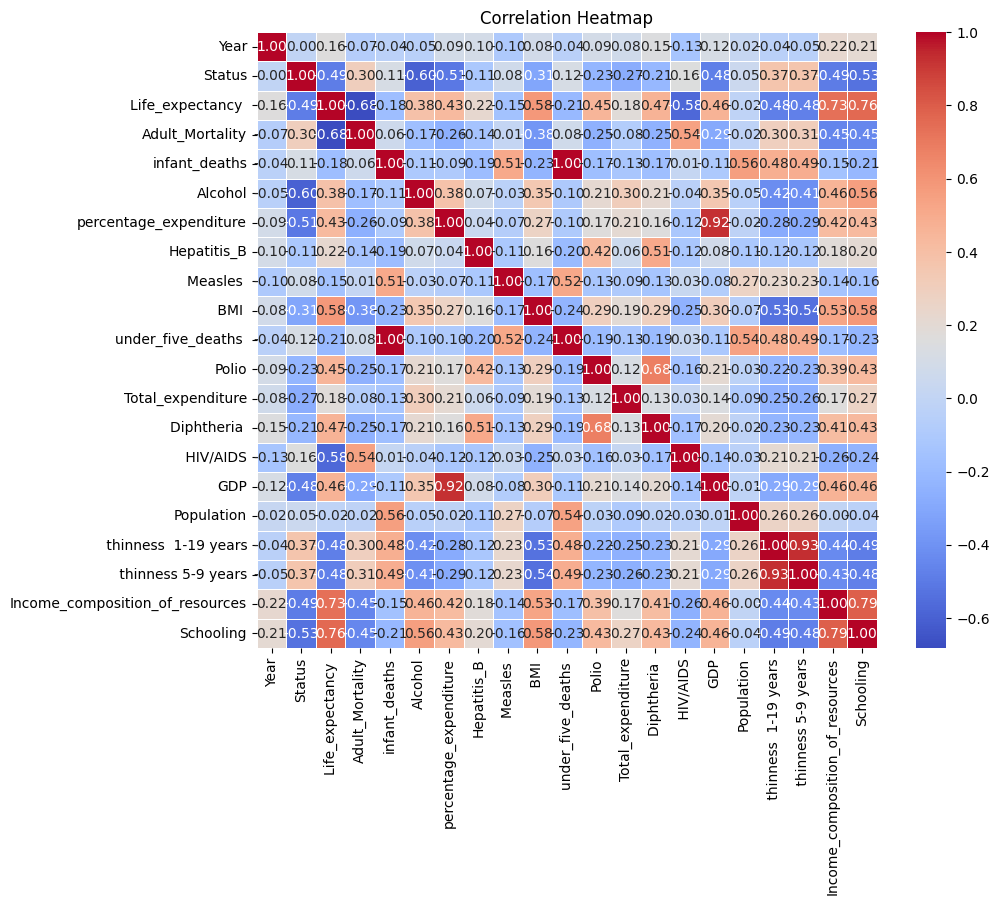

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Обчислення кореляційної матриці без цільової змінної "Continent"
correlation_matrix = df.drop(columns=['Continent']).corr()

# Побудова heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)

plt.title("Correlation Heatmap")
plt.show()

На даному графіку можна побачити що змінні не дуже корелюють одна з одною, тому скоріше за все PCA буде працювати не так ефективно (не має лінійної залежності)

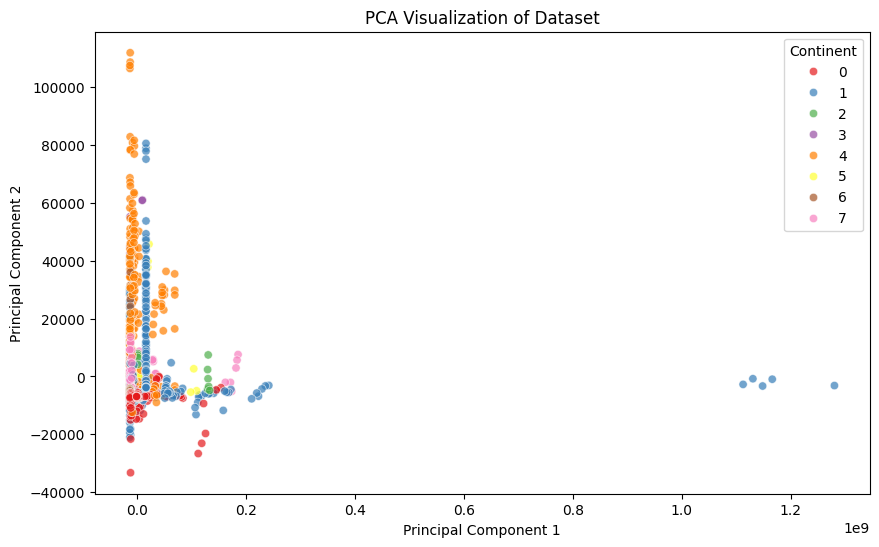

Explained variance ratio: [9.99999909e-01 5.90904963e-08]


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Ініціалізація PCA для двох головних компонент
pca = PCA(n_components=2)

# Застосування PCA (без урахування цільової змінної 'Continent')
X_pca = pca.fit_transform(df.drop(columns=['Continent']))

# Створення нового DataFrame з головними компонентами
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Continent'] = df['Continent']  # Додаємо мітки континентів

# Візуалізація PCA
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue=df_pca['Continent'], palette='Set1', data=df_pca, alpha=0.7)
plt.title('PCA Visualization of Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Continent', bbox_to_anchor=(1, 1))
plt.show()

# Вивід відсотка поясненої дисперсії
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")


In [ ]:
# Відокремлюємо ознаки (X) та цільову змінну (y)
X = df.drop(columns=['Continent'])  # Видаляємо цільову змінну
y = df['Continent']  # Використовуємо закодовані мітки континентів

# Розділяємо дані на навчальну (70%) та тестову (30%) вибірки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Виконуємо PCA, вибираючи кількість головних компонент (наприклад, 5)
pca = PCA(n_components=5)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Навчаємо Random Forest на знижених вимірах
grid_search.fit(X_train_pca, y_train)

GridSearchCV(cv=4,
             estimator=RandomForestClassifier(criterion='entropy',
                                              random_state=42),
             param_grid={'max_depth': [2, 3, 5, 10, 20],
                         'min_samples_leaf': [5, 10, 20, 50, 100, 200],
                         'n_estimators': [5, 10, 25, 30, 50, 100]},
             scoring='accuracy')

In [ ]:
grid_search.best_score_

0.6124094169351753

In [ ]:
rf_best_pca = grid_search.best_estimator_
rf_best_pca

RandomForestClassifier(criterion='entropy', max_depth=20, min_samples_leaf=5,
                       random_state=42)

In [ ]:
# Робимо передбачення
y_pred = rf_best_pca.predict(X_test_pca)

# Оцінюємо точність моделі
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of Random Forest after PCA: {accuracy:.4f}")

Accuracy of Random Forest after PCA: 0.6440


У даному випадку PCA погіршує точність методу Random Forest

In [15]:
df=df.drop(columns="Country")

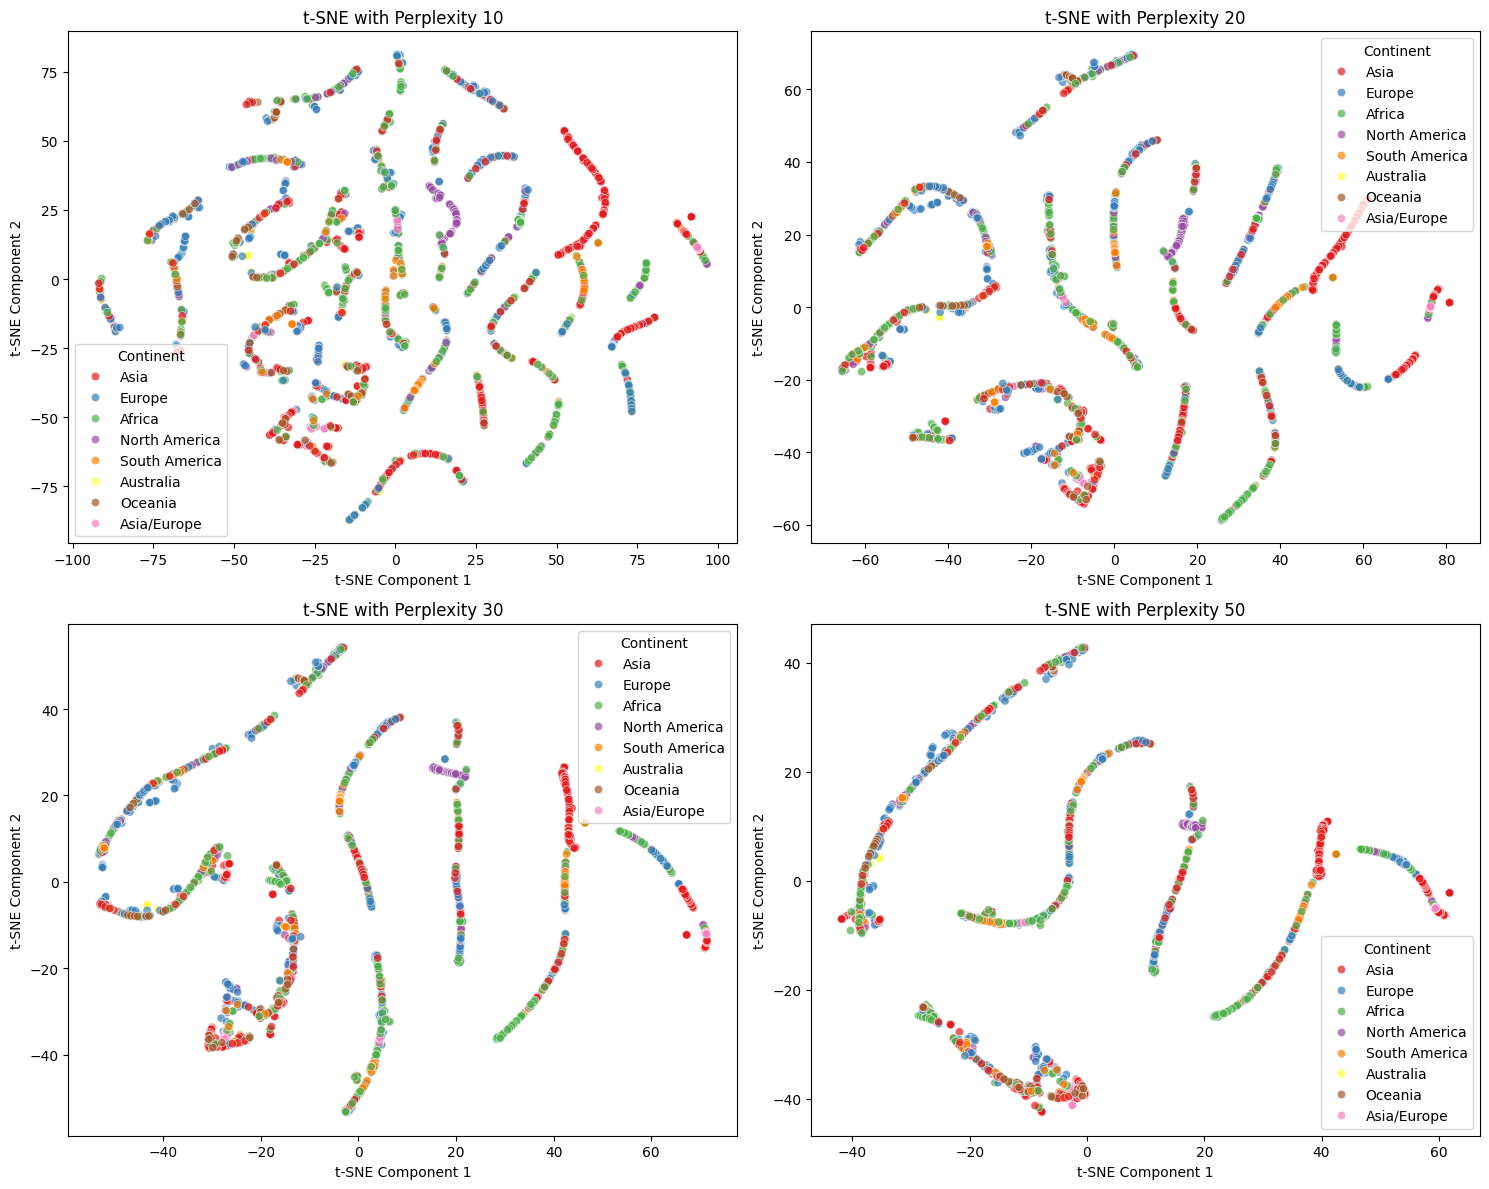

In [19]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# Список значень перплексії
perplexities = [10, 20, 30, 50]

# Створення фігури для 4 графіків
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for i, perplexity in enumerate(perplexities):
    # Ініціалізація t-SNE з відповідною перплексією
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42)
    X_tsne = tsne.fit_transform(df.drop(columns=['Continent']))

    # Створення DataFrame
    df_tsne = pd.DataFrame(X_tsne, columns=['TSNE1', 'TSNE2'])
    df_tsne['Continent'] = df['Continent']

    # Візуалізація t-SNE
    sns.scatterplot(ax=axes[i], x='TSNE1', y='TSNE2', hue=df_tsne['Continent'], palette='Set1', data=df_tsne, alpha=0.7)
    axes[i].set_title(f't-SNE with Perplexity {perplexity}')
    axes[i].set_xlabel('t-SNE Component 1')
    axes[i].set_ylabel('t-SNE Component 2')

plt.tight_layout()
plt.show()

In [20]:
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

# Відокремлюємо ознаки (X) та цільову змінну (y)
X = df.drop(columns=['Continent'])  # Видаляємо цільову змінну
y = df['Continent']  # Використовуємо закодовані мітки континентів

# Розділяємо дані на навчальну (70%) та тестову (30%) вибірки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Ініціалізація t-SNE з перплексією 50
tsne = TSNE(n_components=2, perplexity=50, random_state=42)

# Застосування t-SNE до навчальних та тестових даних
X_train_tsne = tsne.fit_transform(X_train)
X_test_tsne = tsne.fit_transform(X_test)

# Навчаємо Random Forest на знижених вимірах
rf = RandomForestClassifier(random_state=42)
params = {
    'max_depth': [2,3,5,10,20],
    'min_samples_leaf': [5,10,20,50,100,200],
    'n_estimators': [5,10,25,30,50,100]
}

#  Instantiate the grid search model
grid_search = GridSearchCV(estimator=rf,
                           param_grid=params,
                           cv=4,
                           scoring="accuracy")

# Навчаємо модель на тренувальних даних
grid_search.fit(X_train_tsne, y_train)

# Оцінка результатів
grid_search.best_score_

# Найкраща модель після пошуку гіперпараметрів
rf_best_tsne = grid_search.best_estimator_

# Робимо передбачення
y_pred = rf_best_tsne.predict(X_test_tsne)

# Оцінюємо точність моделі
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of Random Forest after t-SNE: {accuracy:.4f}")


Accuracy of Random Forest after t-SNE: 0.2836
